In [1]:
import os
import json
import pandas as pd
while os.getcwd() != '/home/jupyter/crisp':
    os.chdir("..")
%pwd

'/home/jupyter/crisp'

In [2]:
from main import run
from nasa_mice.functions import generate_mouse_human_experiment

In [14]:
verbose = 0
output_data_regime = 'binary' #'real-valued'

In [4]:
data = pd.read_pickle('data/cosmic_rads/human_mice_data_combined.pkl')

In [5]:
data['Characteristics[organism]'].value_counts()

Mus musculus    41
Homo sapiens    21
Name: Characteristics[organism], dtype: int64

In [6]:
max_humans = 21
max_mice = 41

In [7]:
for mice in range(0,41,2):
    generate_mouse_human_experiment(filepath='data/cosmic_rads/human_mice_data_combined.pkl',
                                    human_count = max_humans,
                                    mice_count = mice,
                                    seed = 42,
                                    pickle_directory = 'data/cosmic_rads/vary_mice',
                                    organism_column = 'Characteristics[organism]')

<AxesSubplot:>

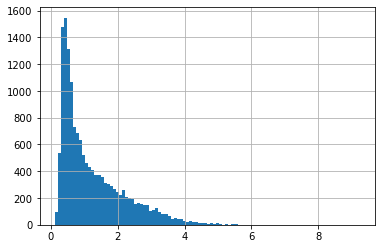

In [8]:
data.std().hist(bins=100)

In [9]:
(data.std() > 2).value_counts()

False    12349
True      3000
dtype: int64

In [10]:
# for experiment in os.listdir('data/cosmic_rads/vary_mice'):
#     if experiment.endswith('.pkl'):
#         print(experiment)
#         merged_data_columns = pd.read_pickle('data/cosmic_rads/vary_mice/'+experiment).columns
#         try:
#             os.mkdir('results/cosmic_rads/vary_mice/'+experiment[:-4]+'/')
#         except Exception as e:
#             print(e)

#         # define config
#         config = {
#             "name": "Example Experiment for AH casual ensemble",
#             "short_name": "ah_experiment_notebook",
#             "bucket_project": "fdl-us-astronaut-health",
#             "bucket_name": "ah_21_data",
#             "bucket_path": "gs://ah_21_data",
#             "verbose": verbose,
#             "test_val_split": [0.1, 0.1],
#             "per_variant_experiment": False,
#             "data_options": {
#                 'synthetic_train_test_split' : False,
#                 'dataset_fp' : 'data/cosmic_rads/vary_mice/'+experiment,
#                 'output_data_regime' : output_data_regime,
#                 'subject_keys': 'Source Name',
#                 'targets': ['irradiated'], #['dose_Gy'],
#                 'predictors': list(data.columns[43:-4]),
#                 'environments': ['environment'],
#                 'exclude': ['organism', 'source', 'gender', 'age_years', 'timepoint_hr', 'dose_Gy', 'radiation', 'dataset','strain']
#             },
#             "feature_selection_options": {
#                 "max_features": 20,
#                 "verbose": verbose,
#                 "seed": 12,
#                 "variance_threshold" : 2, # actually std
#             },
#             "ensemble_options": {
#                 "models": ["IRM","LIRM"],#, "ICP",], # "DCF", "LIRM", "NLICP"],
#                 "LIRM" : {
#                     "use_icp_initialization": False,
#                     "verbose": verbose,
#                     "n_iterations": 1000,
#                     "seed": 0,
#                     "lr": 0.001,
#                     "cuda": False,
#                     "output_data_regime" : output_data_regime,
#                 },
#                 "DCF" : {
#                     "minP": 0.1,
#                     "maxP": 0.9,
#                     "minFeatures": 1,
#                     "minAccuracy": 0.5,
#                     "seed": 0,
#                     "verbose": verbose,
#                     "target": ["Target"],
#                     "output_pvals": False,
#                     "output_data_regime" : output_data_regime,
#                 },
#                 "NLICP" : {
#                     "max_set_size": 2,
#                     "alpha": 0.05,
#                     "seed": 12,
#                     "verbose": verbose,
#                     "method": "MLP",
#                     "hidden_dim": 256,
#                     "output_data_regime" : output_data_regime,
#                 },
#                 "LICP" : {
#                     "max_set_size": 2,
#                     "alpha": 0.05,
#                     "seed": 12,
#                     "verbose": verbose,
#                     "output_data_regime" : output_data_regime,
#                 },
#             },
#              "use_cloud":False,
#             "results_directory": "results/cosmic_rads/vary_mice/"+experiment[:-4]+'/'
#             }
#         print(config['results_directory'])
#         run(config)

In [11]:
for humans in range(0,max_humans,1):
    generate_mouse_human_experiment(filepath='data/cosmic_rads/human_mice_data_combined.pkl',
                                    human_count = humans,
                                    mice_count = max_mice,
                                    seed = 42,
                                    pickle_directory = 'data/cosmic_rads/vary_humans',
                                    organism_column = 'Characteristics[organism]')

humans_1_mice_41_seed_42.pkl
[Errno 17] File exists: 'results/cosmic_rads/vary_humans/humans_1_mice_41_seed_42/'
results/cosmic_rads/vary_humans/humans_1_mice_41_seed_42/
Running Ensemble with the following models:  ['IRM', 'LIRM']


/home/jupyter/crisp/utils/CorrelationToTarget.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_x = np.array(all_x)
/home/jupyter/crisp/utils/CorrelationToTarget.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_y = np.array(all_y)


Checking for features with zero variance
variance threshold is 2
Running correlation analysis
Running Linear IRM
Start IRM training procedure with binary target
Finished Linear IRM
Running IRM
NLIRM using deep MLP2
0               0.82494         0.65146         0.19805      
100             0.64859         0.81520         0.02743      
200             0.66040         0.46433         0.00202      
300             0.71287         0.32749         0.00145      
400             0.67319         0.72632         0.00032      
500             0.67337         0.60702         0.00113      
600             0.70999         0.31813         0.00088      
700             0.69930         0.57544         0.00109      
800             0.68791         0.37544         8.99518e-05  
900             0.69071         0.41520         0.00038      
Finished IRM
Processing Linear IRM
Processing Non-Linear IRM
humans_0_mice_41_seed_42.pkl
[Errno 17] File exists: 'results/cosmic_rads/vary_humans/humans_0_mice_41_s

/home/jupyter/crisp/utils/CorrelationToTarget.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_x = np.array(all_x)
/home/jupyter/crisp/utils/CorrelationToTarget.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_y = np.array(all_y)


Checking for features with zero variance
variance threshold is 2
Running correlation analysis
Running Linear IRM
Start IRM training procedure with binary target
Finished Linear IRM
Running IRM
NLIRM using deep MLP2
0               1.13151         0.50351         0.48672      
100             0.66546         0.72807         0.00790      
200             0.66417         0.76140         0.00129      
300             0.65128         0.64912         0.00069      
400             0.70096         0.62982         0.00332      
500             0.68069         0.57018         0.00012      
600             0.63567         0.65614         0.00203      
700             0.64776         0.72281         0.00248      
800             0.68813         0.49649         7.25957e-06  
900             0.64522         0.64912         0.00184      
Finished IRM
Processing Linear IRM
Processing Non-Linear IRM
humans_18_mice_41_seed_42.pkl
[Errno 17] File exists: 'results/cosmic_rads/vary_humans/humans_18_mice_41

/home/jupyter/crisp/utils/CorrelationToTarget.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_x = np.array(all_x)
/home/jupyter/crisp/utils/CorrelationToTarget.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_y = np.array(all_y)


... (35 outputs left out)

/home/jupyter/crisp/utils/CorrelationToTarget.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_x = np.array(all_x)
/home/jupyter/crisp/utils/CorrelationToTarget.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_y = np.array(all_y)


Checking for features with zero variance
variance threshold is 2
Running correlation analysis
Running Linear IRM
Start IRM training procedure with binary target
Finished Linear IRM
Running IRM
NLIRM using deep MLP2
0               3.59880         0.57475         14.83860     
100             0.69114         0.59436         0.03403      
200             0.66267         0.62091         0.00057      
300             0.70547         0.47753         0.00419      
400             0.65176         0.74346         0.00132      
500             0.69260         0.47876         0.00020      
600             0.67404         0.62786         0.00056      
700             0.69460         0.54657         4.01568e-05  
800             0.69831         0.45670         6.23314e-05  
900             0.69202         0.41503         1.24480e-06  
Finished IRM
Processing Linear IRM
Processing Non-Linear IRM
humans_15_mice_41_seed_42.pkl
[Errno 17] File exists: 'results/cosmic_rads/vary_humans/humans_15_mice_41

/home/jupyter/crisp/utils/CorrelationToTarget.py:24: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_x = np.array(all_x)
/home/jupyter/crisp/utils/CorrelationToTarget.py:25: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  all_y = np.array(all_y)


Checking for features with zero variance
variance threshold is 2
Running correlation analysis
Running Linear IRM
Start IRM training procedure with binary target
Finished Linear IRM
Running IRM
NLIRM using deep MLP2
0               4.51570         0.41667         22.81357     
100             0.71137         0.53922         0.00664      
200             0.68528         0.59804         0.00131      
300             0.67707         0.67320         0.00019      
400             0.68457         0.72059         7.26880e-05  
500             0.68813         0.72059         2.61265e-05  
600             0.68861         0.72059         2.10776e-05  
700             0.69006         0.72059         9.36823e-06  
800             0.68994         0.72059         1.15284e-05  
900             0.68975         0.72059         1.23911e-05  
Finished IRM
Processing Linear IRM
Processing Non-Linear IRM


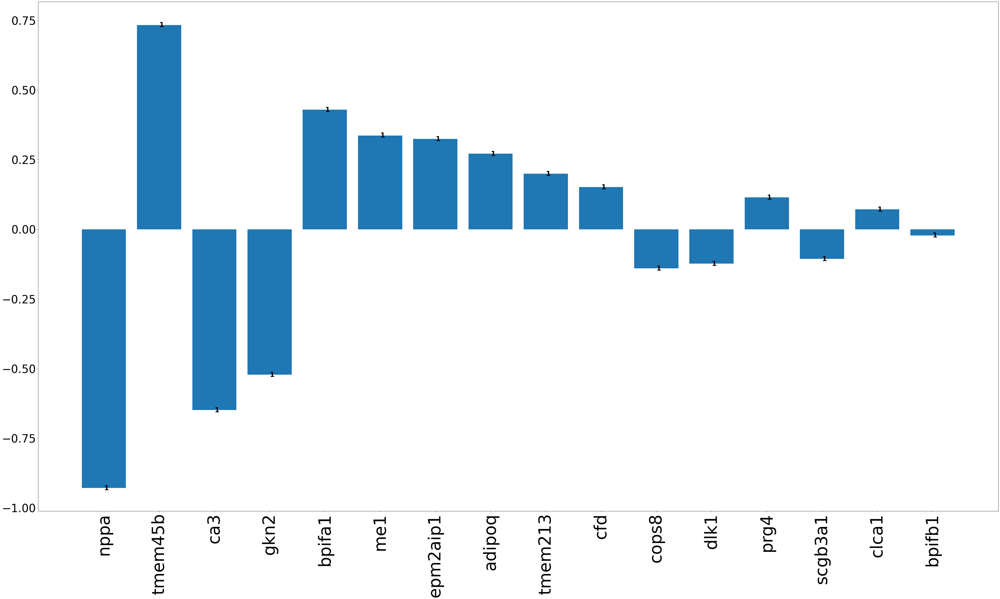

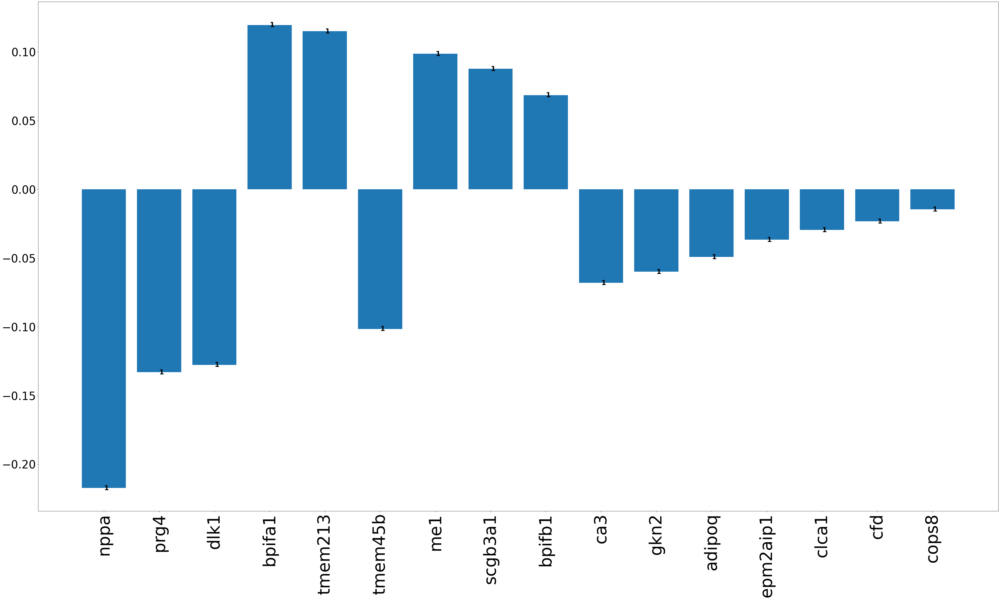

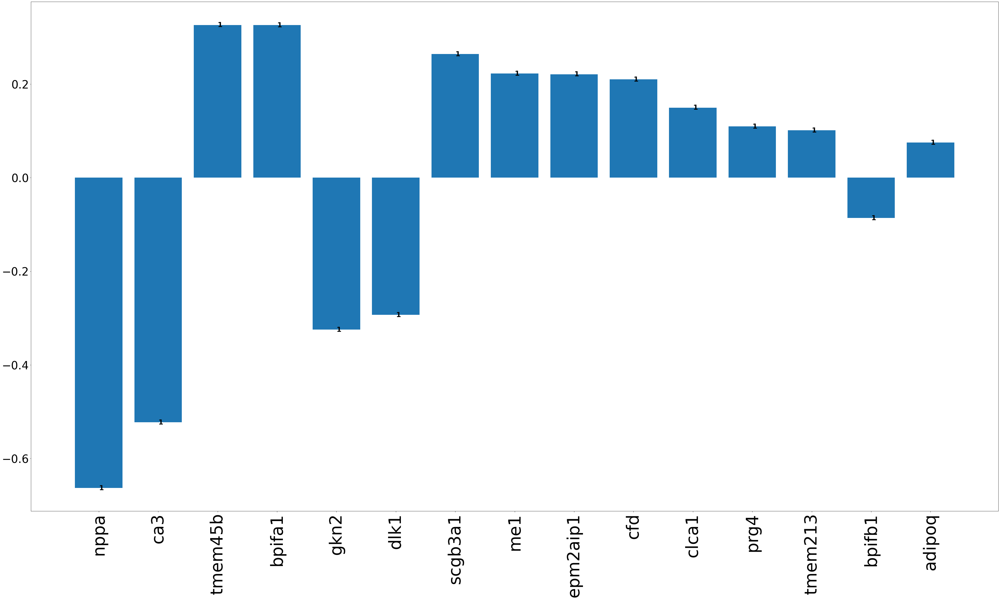

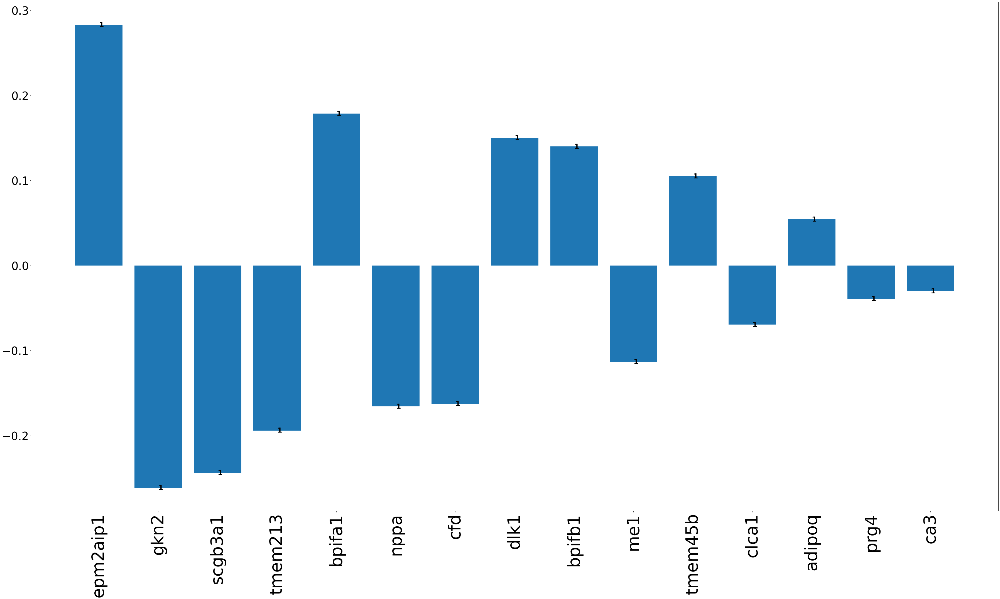

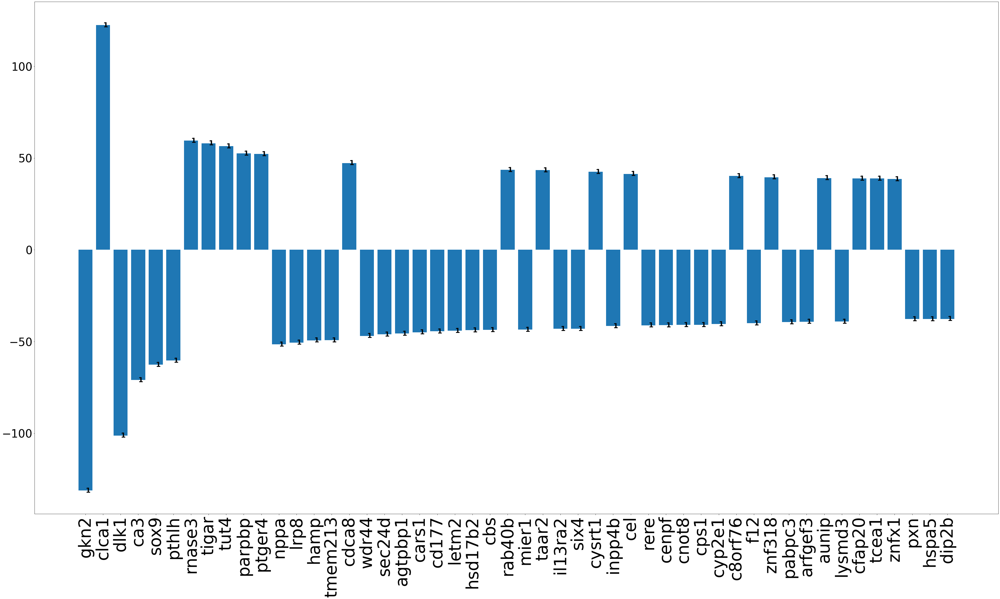

...

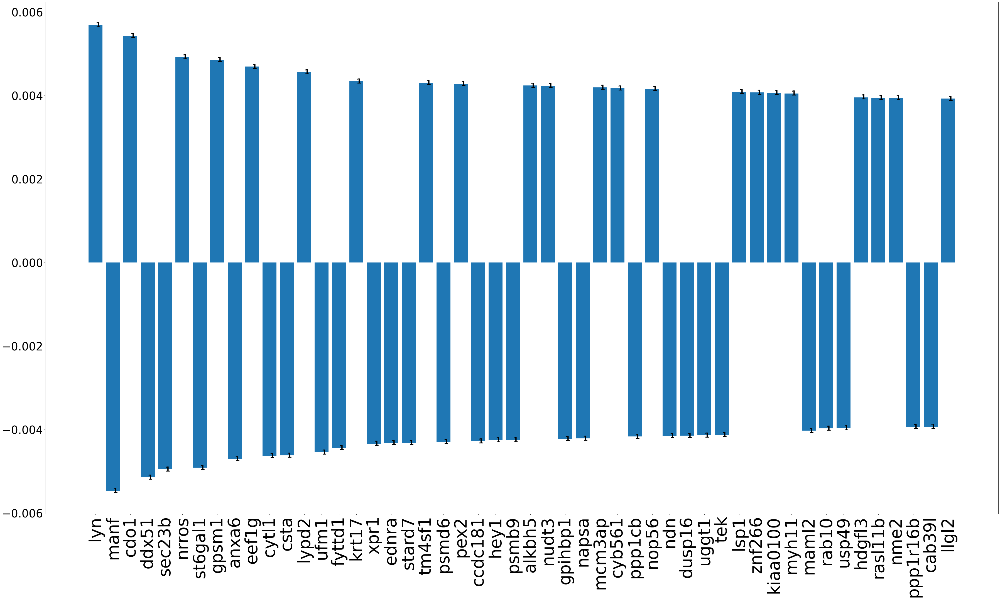

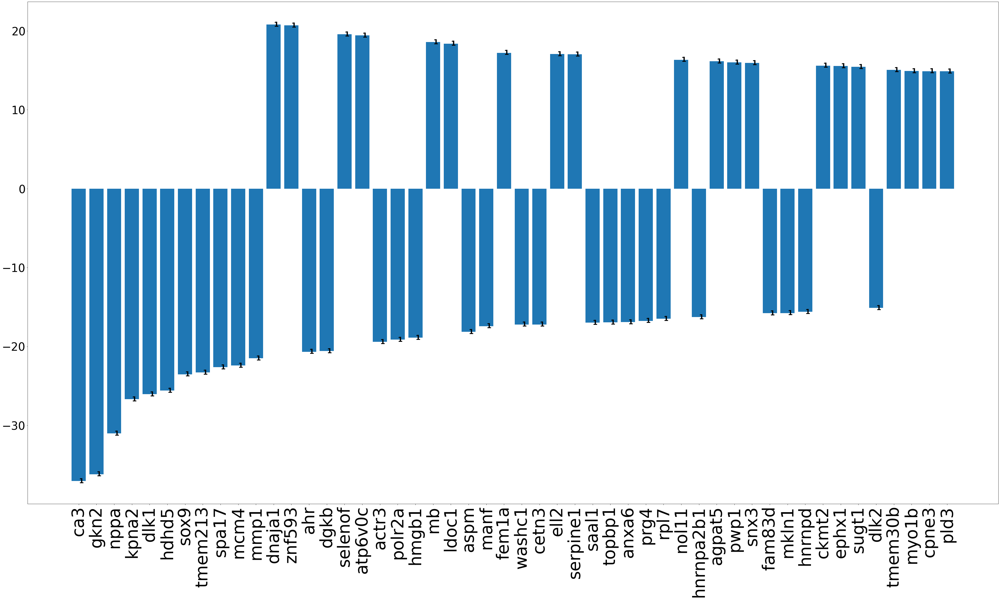

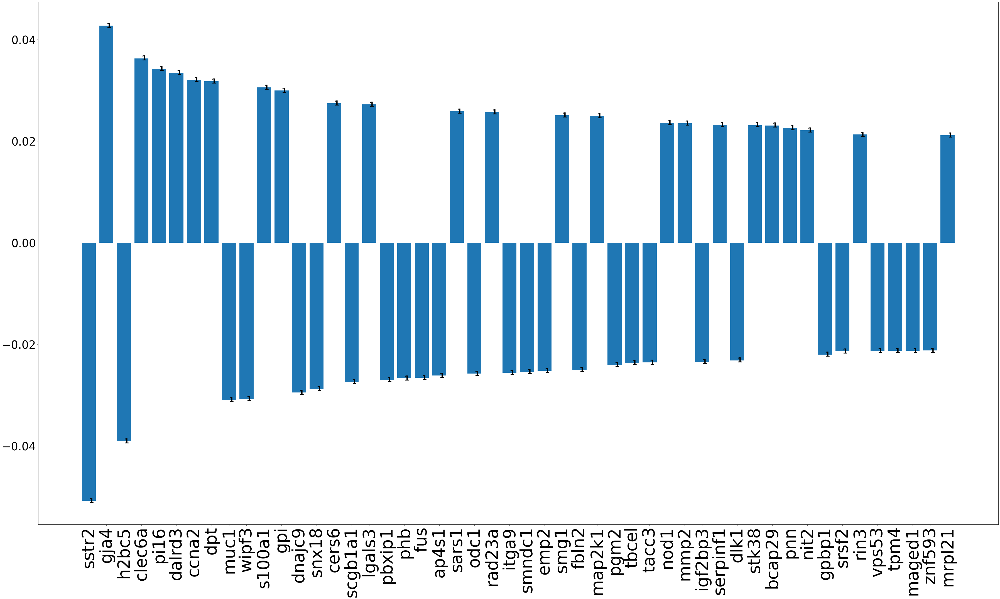

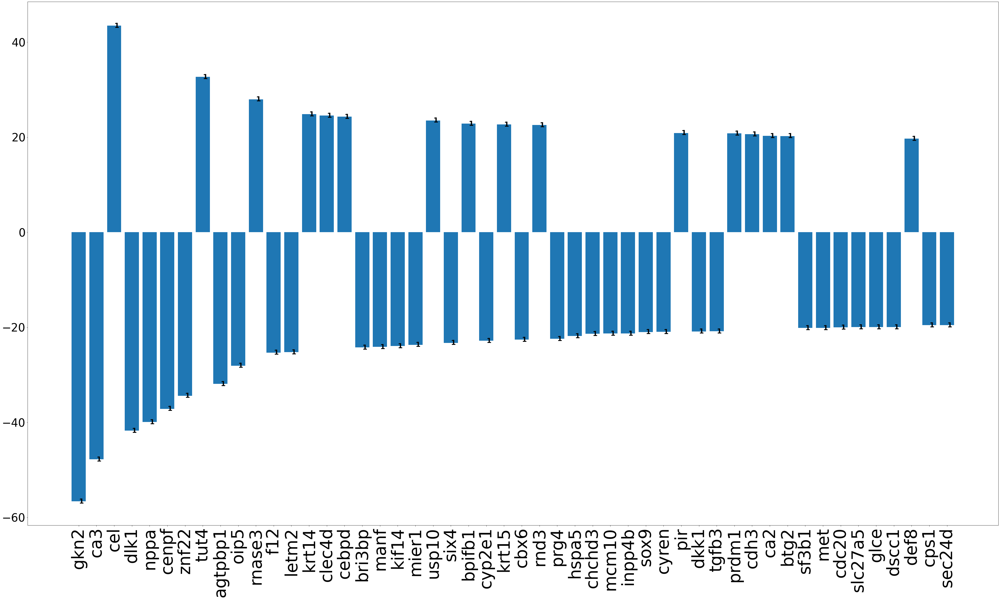

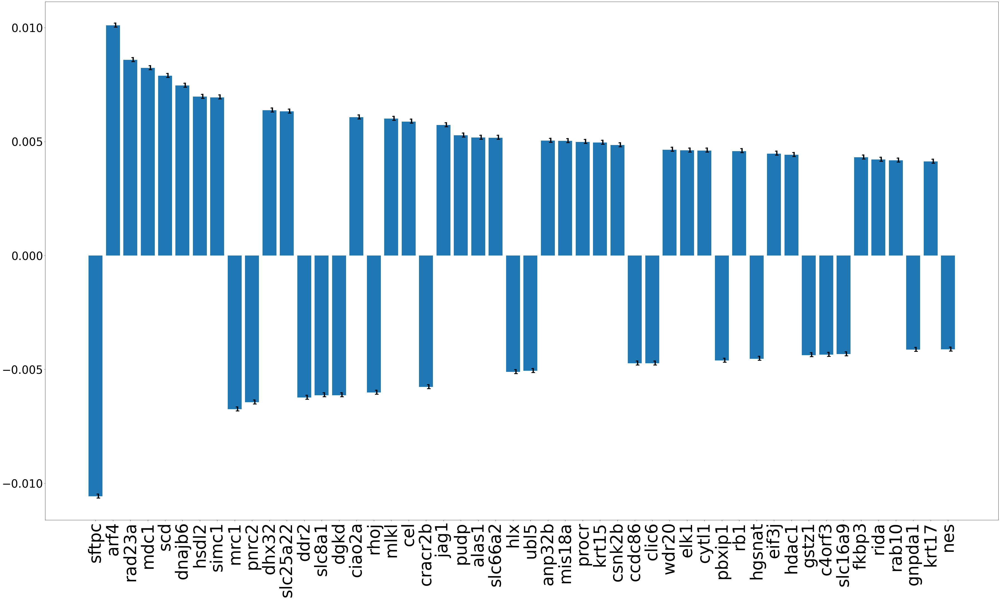

In [15]:
for experiment in os.listdir('data/cosmic_rads/vary_humans'):
    if experiment.endswith('.pkl'):
        print(experiment)
        merged_data_columns = pd.read_pickle('data/cosmic_rads/vary_humans/'+experiment).columns
        try:
            os.mkdir('results/cosmic_rads/vary_humans/'+experiment[:-4]+'/')
        except Exception as e:
            print(e)

        # define config
        config = {
            "name": "Example Experiment for AH casual ensemble",
            "short_name": "ah_experiment_notebook",
            "bucket_project": "fdl-us-astronaut-health",
            "bucket_name": "ah_21_data",
            "bucket_path": "gs://ah_21_data",
            "verbose": verbose,
            "test_val_split": [0.1, 0.1],
            "per_variant_experiment": False,
            "data_options": {
                'synthetic_train_test_split' : False,
                'dataset_fp' : 'data/cosmic_rads/vary_humans/'+experiment,
                'output_data_regime' : output_data_regime,
                'subject_keys': 'Source Name',
                'targets': ['irradiated'], #['dose_Gy'],
                'predictors': list(data.columns[43:-4]),
                'environments': ['environment'],
                'exclude': ['organism', 'source', 'gender', 'age_years', 'timepoint_hr', 'dose_Gy', 'radiation', 'dataset','strain']
            },
            "feature_selection_options": {
                "max_features": 20,
                "verbose": verbose,
                "seed": 12,
                "variance_threshold" : 2, # actually std
            },
            "ensemble_options": {
                "models": ["IRM","LIRM"],#, "ICP",], # "DCF", "LIRM", "NLICP"],
                "LIRM" : {
                    "use_icp_initialization": False,
                    "verbose": verbose,
                    "n_iterations": 1000,
                    "seed": 0,
                    "lr": 0.001,
                    "cuda": False,
                    "output_data_regime" : output_data_regime,
                },
                "DCF" : {
                    "minP": 0.1,
                    "maxP": 0.9,
                    "minFeatures": 1,
                    "minAccuracy": 0.5,
                    "seed": 0,
                    "verbose": verbose,
                    "target": ["Target"],
                    "output_pvals": False,
                    "output_data_regime" : output_data_regime,
                },
                "NLICP" : {
                    "max_set_size": 2,
                    "alpha": 0.05,
                    "seed": 12,
                    "verbose": verbose,
                    "method": "MLP",
                    "hidden_dim": 256,
                    "output_data_regime" : output_data_regime,
                },
                "LICP" : {
                    "max_set_size": 2,
                    "alpha": 0.05,
                    "seed": 12,
                    "verbose": verbose,
                    "output_data_regime" : output_data_regime,
                },
            },
             "use_cloud":False,
            "results_directory": "results/cosmic_rads/vary_humans/"+experiment[:-4]+'/'
            }
        print(config['results_directory'])
        run(config)